# Outliers in hourly electricity load

Blue points are within 3 SD of the mean. Red points have an absolute Z-score greater than 3. The horizontal lines show the mean and the two limits.

The calculations are in `plot_outliers.py`.

In [13]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

cwd = Path.cwd().resolve()
project_root = next(
    (path for path in (cwd, *cwd.parents) if (path / 'plot_outliers.py').is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Run this notebook from the project root or notebooks directory.')

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from plot_outliers import calculate_outliers, plot_outliers

cleaned_dir = project_root / 'data' / 'cleaned'
threshold = 3.0


def plot_cleaned_file(filename):
    """Plot the load values from one cleaned CSV."""
    data = pd.read_csv(cleaned_dir / filename)
    company = filename.removesuffix("_hourly_CLEANED.csv")
    value_columns = [column for column in data.columns if column.endswith('MW')]
    if len(value_columns) != 1:
        raise ValueError(f'{filename}: expected exactly one load column ending in MW.')
    value_column = value_columns[0]
    data = data[['Datetime', value_column]].copy()  # Ignore saved CSV index columns.
    result, fig, ax = plot_outliers(
        data, value_column, date_column='Datetime', threshold=threshold,
        title=f'{company} cleaned hourly load: Z-score outliers',
    )
    mean = result[value_column].mean()
    std = result[value_column].std(ddof=1)
    print(filename)
    print(f'Mean: {mean:,.2f} MW; sample standard deviation: {std:,.2f} MW')
    print(f'Mean ±{threshold:g} SD: [{mean - threshold * std:,.2f}, '
          f'{mean + threshold * std:,.2f}] MW')
    print(f"Outliers: {result['outlier'].sum():,} / {len(result):,} "
          f"({result['outlier'].mean():.2%})")
    plt.show()
    plt.close(fig)
    return result


## AEP

Source: `data/cleaned/AEP_hourly_CLEANED.csv`

FileNotFoundError: [Errno 2] No such file or directory: './figures/AEP cleaned hourly load: Z-score outliers.png'

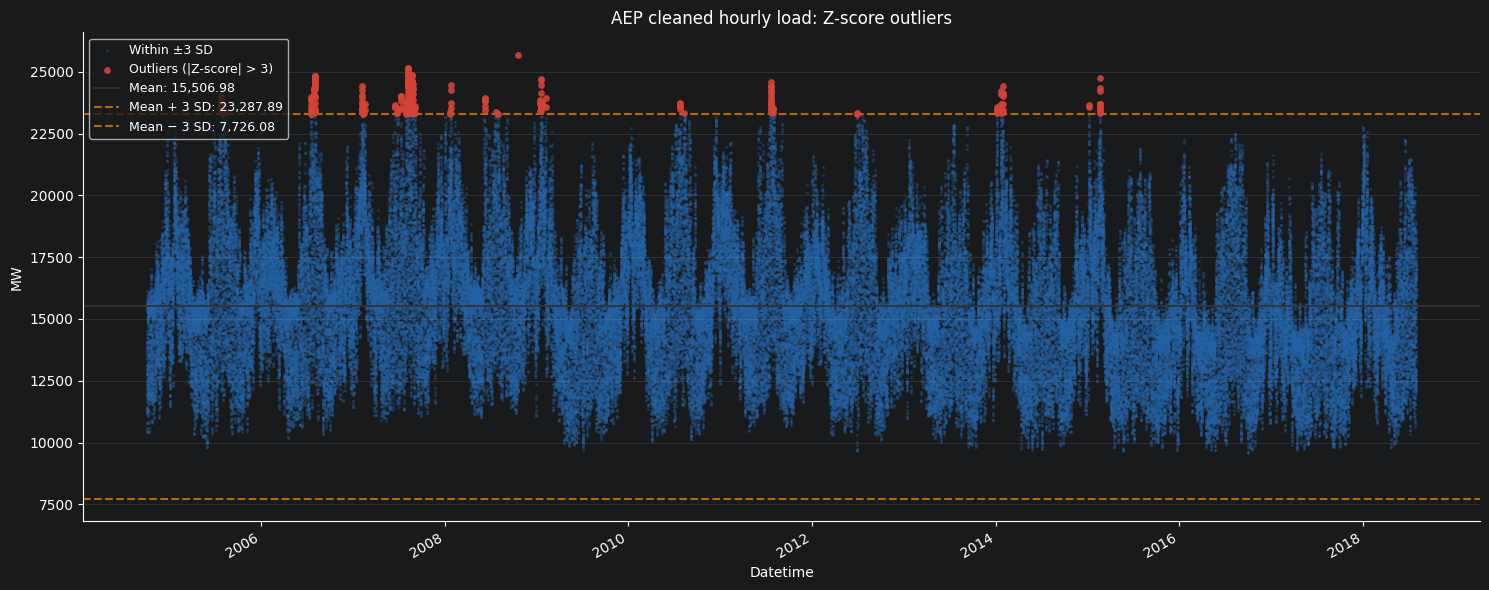

In [14]:
aep = plot_cleaned_file('AEP_hourly_CLEANED.csv')


## COMED

Source: `data/cleaned/COMED_hourly_CLEANED.csv`

In [ ]:
comed = plot_cleaned_file('COMED_hourly_CLEANED.csv')


## DAYTON

Source: `data/cleaned/DAYTON_hourly_CLEANED.csv`

In [ ]:
dayton = plot_cleaned_file('DAYTON_hourly_CLEANED.csv')


## DEOK

Source: `data/cleaned/DEOK_hourly_CLEANED.csv`

In [ ]:
deok = plot_cleaned_file('DEOK_hourly_CLEANED.csv')


## DOM

Source: `data/cleaned/DOM_hourly_CLEANED.csv`

In [ ]:
dom = plot_cleaned_file('DOM_hourly_CLEANED.csv')


## DUQ

Source: `data/cleaned/DUQ_hourly_CLEANED.csv`

In [ ]:
duq = plot_cleaned_file('DUQ_hourly_CLEANED.csv')


## EKPC

Source: `data/cleaned/EKPC_hourly_CLEANED.csv`

In [ ]:
ekpc = plot_cleaned_file('EKPC_hourly_CLEANED.csv')


## FE

Source: `data/cleaned/FE_hourly_CLEANED.csv`

In [ ]:
fe = plot_cleaned_file('FE_hourly_CLEANED.csv')


## NI

Source: `data/cleaned/NI_hourly_CLEANED.csv`

In [ ]:
ni = plot_cleaned_file('NI_hourly_CLEANED.csv')


## PJME

Source: `data/cleaned/PJME_hourly_CLEANED.csv`

In [ ]:
pjme = plot_cleaned_file('PJME_hourly_CLEANED.csv')


## PJM_Load

Source: `data/cleaned/PJM_Load_hourly_CLEANED.csv`

In [ ]:
pjm_load = plot_cleaned_file('PJM_Load_hourly_CLEANED.csv')


## PJMW

Source: `data/cleaned/PJMW_hourly_CLEANED.csv`

In [ ]:
pjmw = plot_cleaned_file('PJMW_hourly_CLEANED.csv')


## All companies combined

Source: `../data/all_data_relabelled_CLEANED.csv`.

The limits use the mean and sample SD of the full dataset. Companies have different load ranges, so these results can differ from the individual plots.

In [ ]:
all_data = pd.read_csv(project_root / 'data' / 'all_data.csv')

all_data, all_data_fig, all_data_ax = plot_outliers(
    all_data, 'MW', date_column='Datetime', threshold=threshold,
    title='All companies combined: Z-score outliers',
)
all_data_mean = all_data['MW'].mean()
all_data_std = all_data['MW'].std(ddof=1)
print('data/all_data.csv')
print(f"Rows: {len(all_data):,}; companies: {all_data['Company'].nunique():,}")
print(f'Mean: {all_data_mean:,.2f} MW; sample standard deviation: {all_data_std:,.2f} MW')
print(f'Mean ±{threshold:g} SD: [{all_data_mean - threshold * all_data_std:,.2f}, '
      f'{all_data_mean + threshold * all_data_std:,.2f}] MW')
print(f"Outliers: {all_data['outlier'].sum():,} / {len(all_data):,} "
      f"({all_data['outlier'].mean():.2%})")
plt.show()
plt.close(all_data_fig)
